# Q3 - Copy Mutate Algorithm with Fitness (Popularity) based Replacement

In [1]:
import os
import random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Parameters
- `N_EPOCHS` = number of epochs
- `NR0` = number of recipes at the start (t = 0)
- `KB_RATIO` = size of kitchen basket / size of nature basket
- `P_MOD`, `P_ADD`, `P_DEL` = chance of modification, addition, deletion (they should add up to 1)
- `MIN_SIZE`, `MAX_SIZE` = a recipe cannot become smaller or bigger than this (same as Q2)
- `MAX_TRIES` = how many times we try to find a fitter ingredient for one modification before we give up and choose the operation again (needed because a recipe may already contain the fittest ingredients of the kitchen basket)
- `N_RUNS` = how many times we run the whole evolution

Plots are saved in the `Q3_output` folder.

In [2]:
DATA_PATH = "ner_ingredient_pairs.csv"
OUTPUT_DIR = "Q3_output"
N_EPOCHS = 10
NR0 = 300
KB_RATIO = 0.02
N_RUNS = 5
SEED = 42

P_MOD = 1 / 3
P_ADD = 1 / 3
P_DEL = 1 / 3
MIN_SIZE = 2
MAX_TRIES = 100

## Load the data
Same as Q2.

In [3]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    DATA_PATH = "/mnt/user-data/uploads/ner_ingredient_pairs.csv"

df = pd.read_csv(DATA_PATH)
df["ingredient"] = df["extracted_ingredient_name"].astype(str).str.strip().str.lower()

real_recipes = df.groupby("recipe_id")["ingredient"].apply(set)
real_sizes = real_recipes.apply(len)

N_RECIPES = len(real_recipes)
NATURE_BASKET = sorted(df["ingredient"].unique())
NB_SIZE = len(NATURE_BASKET)
s = int(round(real_sizes.mean()))
MAX_SIZE = int(real_sizes.max())

print("Number of recipes:", N_RECIPES)
print("Size of nature basket:", NB_SIZE)
print("Starting recipe size s:", s)
print("MIN_SIZE and MAX_SIZE:", MIN_SIZE, MAX_SIZE)

Number of recipes: 7538
Size of nature basket: 5893
Starting recipe size s: 13
MIN_SIZE and MAX_SIZE: 2 45


## Fitness of the ingredients
Fitness of an ingredient = its **popularity** in the real data = (number of real recipes that contain the ingredient) / (total number of real recipes). 

So an ingredient used in many recipes has a high fitness and a rare ingredient has a low fitness. Every ingredient of the Nature Basket gets a fitness value.

In [4]:
real_counts = df.drop_duplicates(["recipe_id", "ingredient"])["ingredient"].value_counts()
FITNESS = {ing: real_counts[ing] / N_RECIPES for ing in NATURE_BASKET}

print("Number of ingredients with fitness:", len(FITNESS))
print("Max fitness:", round(max(FITNESS.values()), 4), "| Min fitness:", round(min(FITNESS.values()), 6))
print("Top 10 fittest ingredients:")
for ing, f in sorted(FITNESS.items(), key=lambda x: -x[1])[:10]:
    print("   ", ing, round(f, 4))

Number of ingredients with fitness: 5893
Max fitness: 0.7085 | Min fitness: 0.000133
Top 10 fittest ingredients:
    salt 0.7085
    water 0.4349
    oil 0.3997
    garlic 0.2465
    ginger 0.2211
    onion 0.219
    ghee 0.2014
    sugar 0.1865
    cumin seeds 0.1614
    turmeric powder 0.1548


## Epochs, recipes per epoch and kitchen basket size
Same as Q1 and Q2.

In [5]:
RECIPES_PER_EPOCH = round(N_RECIPES / N_EPOCHS)

epoch_targets = []
for k in range(1, N_EPOCHS + 1):
    epoch_targets.append(min(k * RECIPES_PER_EPOCH, N_RECIPES))

KB_SIZE = max(round(KB_RATIO * NB_SIZE), s + 1)

print("Recipes per epoch:", RECIPES_PER_EPOCH)
print("Target recipes at end of each epoch:", epoch_targets)
print("Kitchen basket size:", KB_SIZE)

Recipes per epoch: 754
Target recipes at end of each epoch: [754, 1508, 2262, 3016, 3770, 4524, 5278, 6032, 6786, 7538]
Kitchen basket size: 118


## Primordial cuisine (epoch 0)
Same as Q1 and Q2.

In [6]:
def make_primordial(rng):
    kb = rng.sample(NATURE_BASKET, KB_SIZE)
    recipes = []
    seen = set()
    while len(recipes) < NR0:
        r = rng.sample(kb, s)
        key = frozenset(r)
        if key not in seen:
            seen.add(key)
            recipes.append(r)
    return kb, recipes, seen

## Modification (with fitness), addition and deletion
`mutate` copies the recipe and then picks one of the three operations randomly using the probabilities.

- **Modification (changed from Q2):** pick a random ingredient of the recipe (old) and a random ingredient of the kitchen basket (new). The replacement is done **only if the new ingredient is fitter than the old one** (`FITNESS[new] > FITNESS[old]`) and it is not already in the recipe. Otherwise we pick again. This is tried at most `MAX_TRIES` times. If no fitter ingredient is found, `modify` returns `None` and `mutate` chooses the operation again. Size stays same.
- **Addition:** same as Q2 - add a random kitchen basket ingredient which is not in the recipe. Not done if the recipe already has `MAX_SIZE` ingredients.
- **Deletion:** same as Q2 - remove a random ingredient. Not done if the recipe has only `MIN_SIZE` ingredients.

In [8]:
def modify(child, kb, rng):
    # replace an ingredient only with a FITTER ingredient from the kitchen basket
    for _ in range(MAX_TRIES):
        pos = rng.randrange(len(child))
        old_ing = child[pos]
        new_ing = rng.choice(kb)
        if new_ing not in child and FITNESS[new_ing] > FITNESS[old_ing]:
            child[pos] = new_ing
            return child
    return None                    # no fitter ingredient found, try another operation


def add(child, kb, rng):
    while True:
        new_ing = rng.choice(kb)
        if new_ing not in child:
            child.append(new_ing)
            return child


def delete(child, rng):
    pos = rng.randrange(len(child))
    child.pop(pos)
    return child


def mutate(parent, kb, rng):
    child = list(parent)          # copy of the recipe
    while True:
        x = rng.random()
        if x < P_MOD:
            result = modify(child, kb, rng)
            if result is not None:
                return result
        elif x < P_MOD + P_ADD:
            if len(child) < MAX_SIZE:
                return add(child, kb, rng)
        else:
            if len(child) > MIN_SIZE:
                return delete(child, rng)

##  Evolution of the cuisine
Same loop as Q2: pick a random recipe, mutate it, and add the new recipe to the cuisine only if it is not already there. Statistics are saved at the end of every epoch. `counts` stores in how many recipes each ingredient is present.

In [9]:
def get_stats(recipes, counts):
    # recipe size distribution and normalised frequency (sorted high to low)
    n = len(recipes)
    size_count = Counter(len(r) for r in recipes)
    freq = sorted(counts.values(), reverse=True)
    freq = np.array(freq) / n
    return {"n": n, "size_count": size_count, "freq": freq}


def run_cuisine(seed):
    rng = random.Random(seed)
    kb, recipes, seen = make_primordial(rng)
    counts = Counter()                      # in how many recipes each ingredient is present
    for r in recipes:
        counts.update(r)

    all_epochs = []
    for target in epoch_targets:
        while len(recipes) < target:
            parent = rng.choice(recipes)
            child = mutate(parent, kb, rng)
            key = frozenset(child)
            if key in seen:                 # recipe already there, skip it
                continue
            seen.add(key)
            recipes.append(child)
            counts.update(child)
        all_epochs.append(get_stats(recipes, counts))   # save stats at end of epoch
    return all_epochs

## One run - plots for each epoch
Recipe size distribution and normalised frequency-rank distribution for every epoch (one run).

In [10]:
run0 = run_cuisine(SEED)
print("recipes in final cuisine:", run0[-1]["n"])
print("ingredients used in final cuisine:", len(run0[-1]["freq"]))

sizes_final = []
for size, c in run0[-1]["size_count"].items():
    sizes_final += [size] * c
print("final recipe size: min", min(sizes_final), "max", max(sizes_final), "mean", round(np.mean(sizes_final), 2))

recipes in final cuisine: 7538
ingredients used in final cuisine: 118
final recipe size: min 8 max 19 mean 13.03


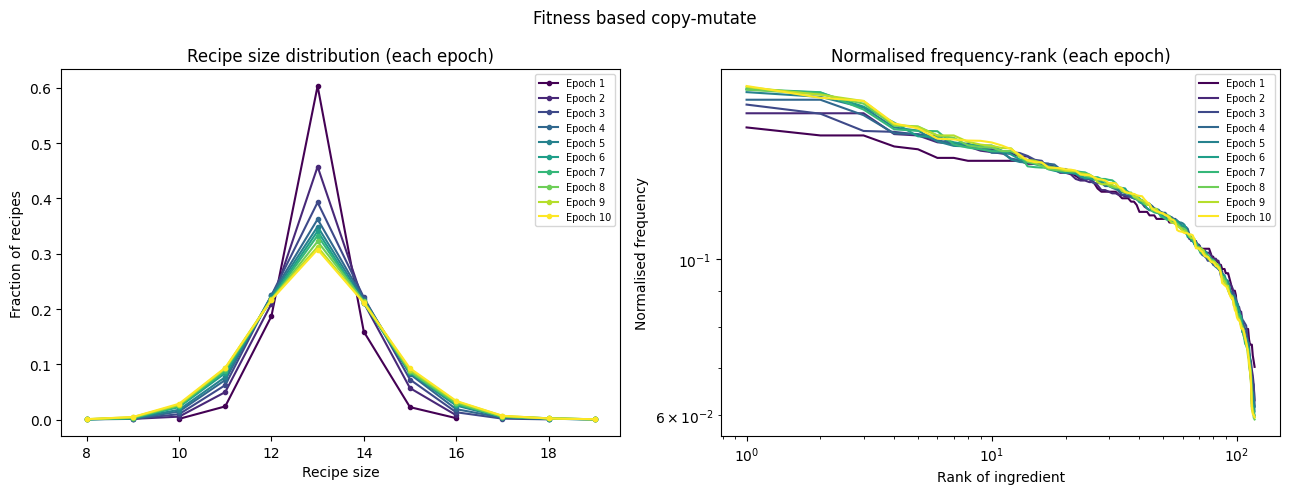

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.viridis(np.linspace(0, 1, N_EPOCHS))

for i in range(N_EPOCHS):
    st = run0[i]
    sz = sorted(st["size_count"])
    frac = [st["size_count"][x] / st["n"] for x in sz]
    ax1.plot(sz, frac, "o-", color=colors[i], markersize=3, label="Epoch " + str(i + 1))

    ranks = np.arange(1, len(st["freq"]) + 1)
    ax2.loglog(ranks, st["freq"], color=colors[i], label="Epoch " + str(i + 1))

ax1.set_xlabel("Recipe size")
ax1.set_ylabel("Fraction of recipes")
ax1.set_title("Recipe size distribution (each epoch)")
ax1.legend(fontsize=7)

ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Normalised frequency-rank (each epoch)")
ax2.legend(fontsize=7)

plt.suptitle("Fitness based copy-mutate")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q3_Fig1_RecipeSize_FreqRank_per_Epoch.png"), dpi=200)
plt.show()

## Run 5 instances
Run the whole evolution 5 times with different seeds and use the final epoch of every run.

In [13]:
runs = []
for r in range(N_RUNS):
    runs.append(run_cuisine(SEED + r))
    print("run", r + 1, "done")

final = [run[-1] for run in runs]

run 1 done
run 2 done
run 3 done
run 4 done
run 5 done


## Recipe size distribution (mean and std)
Fraction of recipes of each size in every run, then mean and std over the 5 runs. Grey bars are the real data.

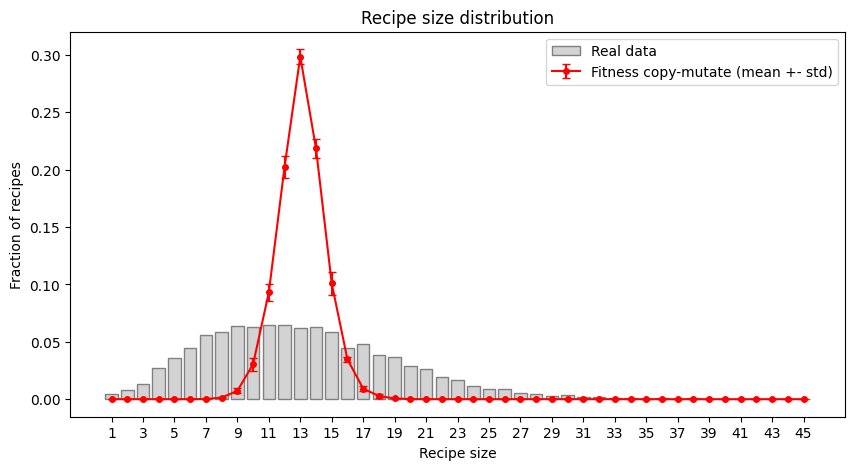

In [14]:
sizes = np.arange(1, MAX_SIZE + 1)

all_frac = []
for f in final:
    row = [f["size_count"].get(x, 0) / f["n"] for x in sizes]
    all_frac.append(row)
all_frac = np.array(all_frac)

mean_size = all_frac.mean(axis=0)
std_size = all_frac.std(axis=0)

real_frac = [(real_sizes == x).mean() for x in sizes]

plt.figure(figsize=(10, 5))
plt.bar(sizes, real_frac, color="lightgrey", edgecolor="grey", label="Real data")
plt.errorbar(sizes, mean_size, yerr=std_size, fmt="o-", color="red", markersize=4, capsize=3, label="Fitness copy-mutate (mean +- std)")
plt.xticks(sizes[::2])
plt.xlabel("Recipe size")
plt.ylabel("Fraction of recipes")
plt.title("Recipe size distribution")
plt.legend()
plt.savefig(os.path.join(OUTPUT_DIR, "Q3_Fig2_RecipeSizeDistribution_MeanSD.png"), dpi=200)
plt.show()

## Normalised frequency-rank distribution
Normalised frequency = (number of recipes having the ingredient) / (total recipes). Sorted high to low and plotted against rank on log-log scale. Left: full view with the real data (grey). Right: zoom on the simulated part so that the std can be seen.

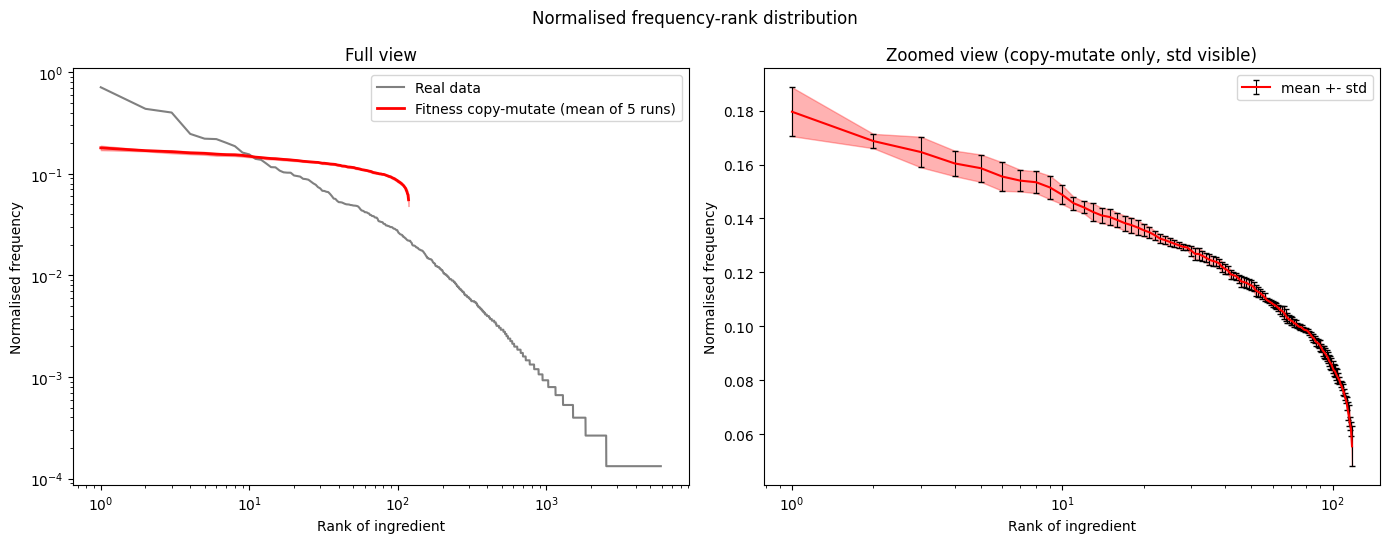

In [15]:
L = min(len(f["freq"]) for f in final)          # same number of ranks for all runs
F = np.array([f["freq"][:L] for f in final])
mean_f = F.mean(axis=0)
std_f = F.std(axis=0)
ranks = np.arange(1, L + 1)

# real data
real_freq = real_counts.values / N_RECIPES

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

ax1.loglog(np.arange(1, len(real_freq) + 1), real_freq, color="grey", label="Real data")
ax1.loglog(ranks, mean_f, color="red", linewidth=2, label="Fitness copy-mutate (mean of 5 runs)")
ax1.fill_between(ranks, np.clip(mean_f - std_f, 1e-6, None), mean_f + std_f, color="red", alpha=0.3)
ax1.set_xlabel("Rank of ingredient")
ax1.set_ylabel("Normalised frequency")
ax1.set_title("Full view")
ax1.legend()

ax2.errorbar(ranks, mean_f, yerr=std_f, fmt="-", color="red", ecolor="black", elinewidth=0.8, capsize=2, label="mean +- std")
ax2.fill_between(ranks, mean_f - std_f, mean_f + std_f, color="red", alpha=0.3)
ax2.set_xscale("log")
ax2.set_xlabel("Rank of ingredient")
ax2.set_ylabel("Normalised frequency")
ax2.set_title("Zoomed view (copy-mutate only, std visible)")
ax2.legend()

plt.suptitle("Normalised frequency-rank distribution")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Q3_Fig3_NormalisedFreqRank.png"), dpi=200)
plt.show()